Eddy Guo

eyguo-code

8913122458

## for HW 4 scroll down

1.c.i

From research on the internet, some features usually used in time series classification include: 
- Minimum and Maximum
- Mean 
- Median
- Variance and Standard Deviation
- Skewness
- Kurtosis
- Autocorrelation
- Partial Autocorrelation
- Zero-Crossing Rate
- Root Mean Square
- Hjorth Parameters like Comprises Activity, Mobility, Complexity 

1.c.ii

In [1]:
import pandas as pd
from pathlib import Path
import numpy as np

data_dir = Path(
    "../Data/activity+recognition+system+based+on+multisensor+data+fusion+arem"
)

csv_files = sorted(data_dir.rglob("*.csv"))

# print(f"Found {len(csv_files)} CSV files")

statistics = [
    "min", "max", "mean", "median",
    "std", "1st_quart", "3rd_quart"
]

feature_columns = [
    f"{stat}{i}"
    for i in range(1, 7)
    for stat in statistics
]

feature_rows = []

for file_path in csv_files:

    df = pd.read_csv(
        file_path,
        skiprows=5,
        header=None,
        usecols=range(1, 7),
        sep=r",\s*|\s+",
        engine="python"
    )

    row = []

    for col in df.columns:
        series = pd.to_numeric(df[col], errors="coerce")

        row.extend([
            series.min(),
            series.max(),
            series.mean(),
            series.median(),
            series.std(),
            series.quantile(0.25),
            series.quantile(0.75)
        ])

    feature_rows.append(row)

features_df = pd.DataFrame(
    feature_rows,
    columns=feature_columns
)

features_df.insert(
    0, "Instance", range(1, len(features_df) + 1)
)

# print("Final dataset shape:", features_df.shape)
display(features_df)


,Instance,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,1,37.25,45.00,40.624792,40.500,1.476967,39.25,42.0000,0.0,1.30,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.430,0.582915,0.00,1.3000
1,2,38.00,45.67,42.812812,42.500,1.435550,42.00,43.6700,0.0,1.22,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.430,0.601010,0.00,1.3000
2,3,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,0.0,1.70,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.430,0.513506,0.00,0.9400
3,4,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,0.0,3.00,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.500,0.524317,0.00,1.0000
4,5,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,0.0,2.83,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.430,0.389164,0.00,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,84,20.75,46.25,34.763333,35.290,4.742208,31.67,38.2500,0.0,12.68,...,3.174681,14.2500,18.33,0.0,9.39,3.288271,3.270,1.647528,2.05,4.3050
84,85,21.50,51.00,34.935812,35.500,4.645944,32.00,38.0625,0.0,12.21,...,3.192058,14.2375,18.25,0.0,10.21,3.280021,3.015,1.700918,2.12,4.5000
85,86,18.33,47.67,34.333042,34.750,4.948770,31.25,38.0000,0.0,12.48,...,3.000493,13.7500,18.00,0.0,8.01,3.261583,2.980,1.617290,2.05,4.3200
86,87,18.33,45.75,34.599875,35.125,4.731790,31.50,38.0000,0.0,15.37,...,2.905688,14.0000,18.25,0.0,8.86,3.289542,3.015,1.680170,2.12,4.2600


1.c.iii.

In [2]:
X = features_df.drop(columns=["Instance"])

n_bootstrap = 10000
confidence_level = 0.90
rng = np.random.default_rng(42)

results = []

for feature in X.columns:
    data = X[feature].dropna().to_numpy()
    n = len(data)

    estimated_std = np.std(data, ddof=1)

    bootstrap_stds = []

    for _ in range(n_bootstrap):
        sample = rng.choice(data, size=n, replace=True)
        bootstrap_stds.append(np.std(sample, ddof=1))

    lower_bound = np.percentile(bootstrap_stds, 5)
    upper_bound = np.percentile(bootstrap_stds, 95)

    results.append({
        "Feature": feature,
        "Estimated Std": estimated_std,
        "90% CI Lower": lower_bound,
        "90% CI Upper": upper_bound
    })

std_ci_df = pd.DataFrame(results)

display(std_ci_df.round(4))


,Feature,Estimated Std,90% CI Lower,90% CI Upper
0,min1,9.5700,8.2591,10.7762
1,max1,4.3944,3.3417,5.2936
2,mean1,5.3357,4.6993,5.8818
3,median1,5.4401,4.7910,5.9913
4,std1,1.7722,1.5726,1.9492
5,1st_quart1,6.1536,5.5814,6.6466
6,3rd_quart1,5.1389,4.3177,5.8483
7,min2,0.0000,0.0000,0.0000
8,max2,5.0627,4.6241,5.4018
9,mean2,1.5742,1.3929,1.7071


1.c.iv.

For this dataset and the information form the previous cells, I could only choose max, mean, and std dev.

2.

3.7.4.

(a) The cubic model would have at most the same RSS as the linear one. This is because there are more polynomial terms in the cubic model that allows it to possibly fit some noise more than the linear model. 

(b) For the test RSS, the linear model would have lower RSS. This is because the true relationship is linear and thus the cubic model might overfit.

(c) We would still expect the cubic model to have lower training RSS due to its flexibility. 

(d) We would need more information to judge. 

# **HW 4**

In [3]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from matplotlib.lines import Line2D
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
import statsmodels.api as sm
import warnings
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import classification_report
from scipy.special import expit
from scipy.special import logit
from sklearn.exceptions import ConvergenceWarning
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import MinMaxScaler

2.a.i

In [4]:
data_dir = Path(
    "../Data/activity+recognition+system+based+on+multisensor+data+fusion+arem"
)


csv_files = sorted(data_dir.rglob("*.csv"))

assert len(csv_files) == len(features_df) == 88


metadata = []

for file in csv_files:
    activity = file.parent.name
    dataset_num = int(file.stem.replace("dataset", ""))


    if activity in ["bending1", "bending2"]:
        is_test = dataset_num in [1, 2]
    else:
        is_test = dataset_num in [1, 2, 3]

    metadata.append({
        "activity": activity,
        "class": "bending" if activity.startswith("bending") else "other",
        "is_test": is_test
    })


full_df = pd.concat([
    features_df.reset_index(drop=True),
    pd.DataFrame(metadata)
], axis=1)


train_df = full_df[~full_df["is_test"]].copy()
test_df = full_df[full_df["is_test"]].copy()


print("Training instances:", len(train_df))
print("Test instances:", len(test_df))

print("\nTraining class distribution:")
print(train_df["class"].value_counts())

print("\nTest class distribution:")
print(test_df["class"].value_counts())

Training instances: 69
Test instances: 19

Training class distribution:
class
other      60
bending     9
Name: count, dtype: int64

Test class distribution:
class
other      15
bending     4
Name: count, dtype: int64


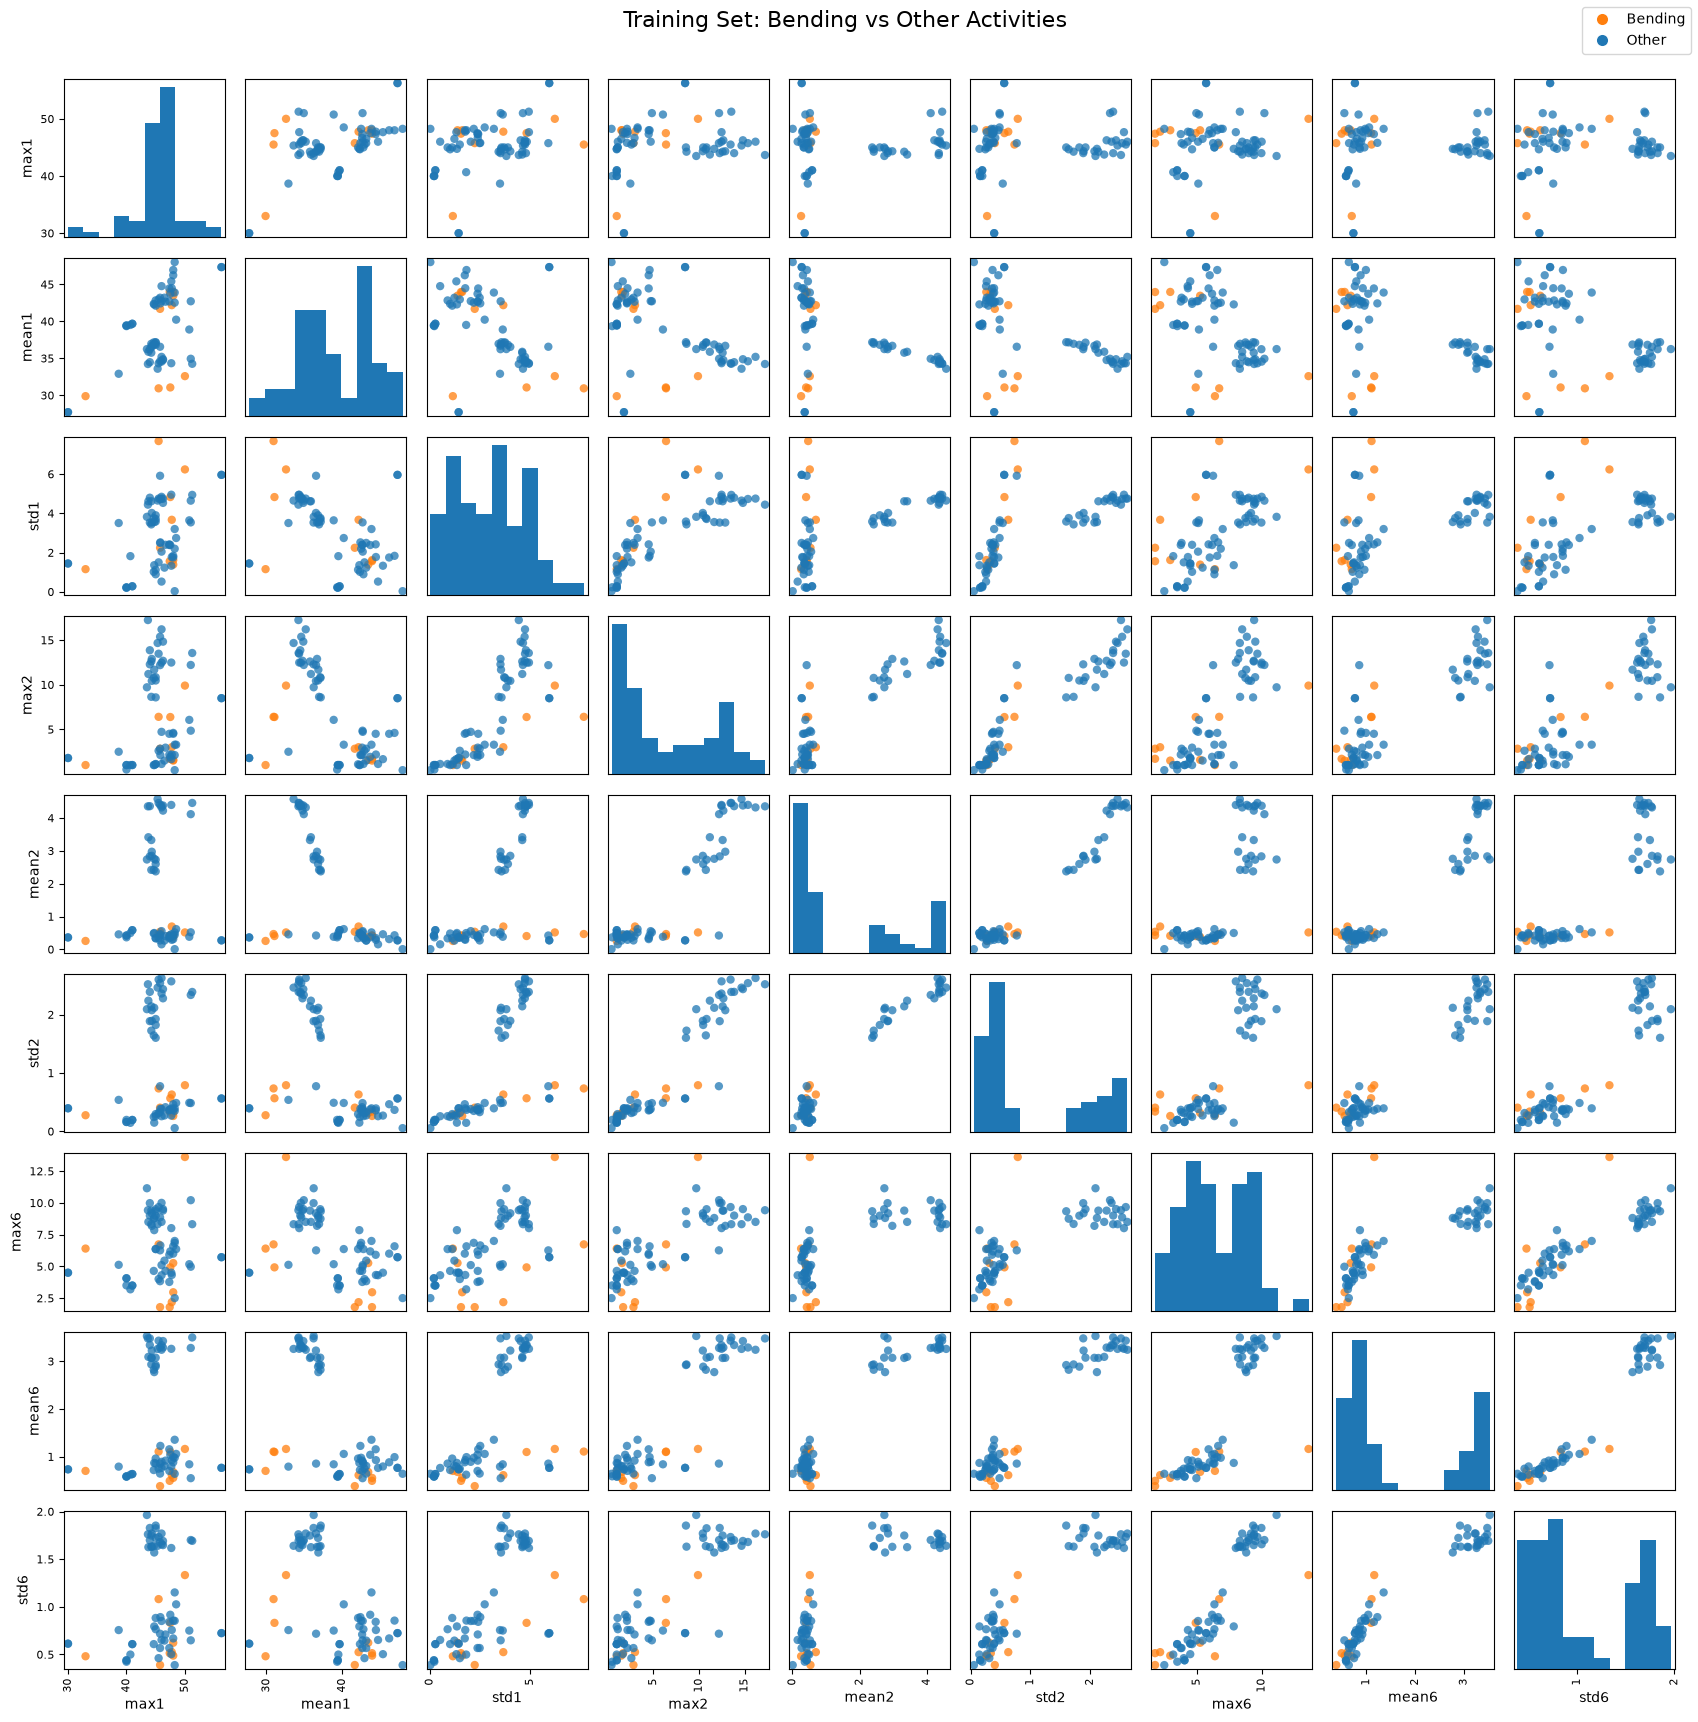

In [5]:
selected_features = [
    "max1", "mean1", "std1",
    "max2", "mean2", "std2",
    "max6", "mean6", "std6"
]

colors = train_df["class"].map({
    "bending": "tab:orange",
    "other": "tab:blue"
})

axes = scatter_matrix(
    train_df[selected_features],
    figsize=(17, 17),
    diagonal="hist",
    c=colors,
    alpha=0.75,
    marker="o"
)

legend = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="tab:orange", label="Bending",
           markersize=9),
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="tab:blue", label="Other",
           markersize=9)
]

fig = axes[0, 0].get_figure()
fig.legend(handles=legend, loc="upper right")

fig.suptitle(
    "Training Set: Bending vs Other Activities",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

2.a.ii

Training instances: 69
Number of extracted features: 18


,max1_part1,mean1_part1,std1_part1,max1_part2,mean1_part2,std1_part2,max2_part1,mean2_part1,std2_part1,max2_part2,mean2_part2,std2_part2,max6_part1,mean6_part1,std6_part1,max6_part2,mean6_part2,std6_part2,class
0,46.50,44.057167,1.556971,47.40,43.851833,1.557168,1.50,0.381042,0.329540,1.70,0.471458,0.342346,1.79,0.598250,0.526656,1.50,0.388333,0.478528,bending
1,47.75,43.278875,3.473355,46.00,41.080750,3.537481,3.00,0.673292,0.634285,2.86,0.718792,0.627915,1.53,0.640958,0.554542,2.18,0.586083,0.491873,bending
2,45.75,41.621208,3.118644,43.67,41.734917,0.595920,2.83,0.623083,0.489595,1.12,0.448875,0.273050,1.79,0.419083,0.411200,1.50,0.347500,0.363144,bending
3,48.00,44.117042,1.359836,46.50,42.792875,1.058792,1.30,0.250042,0.314099,1.58,0.506125,0.260761,5.26,0.815417,0.718016,4.06,0.543875,0.473445,bending
4,45.00,43.486208,1.281976,48.00,44.452042,1.771251,1.30,0.378667,0.284434,1.50,0.447583,0.235493,2.28,0.524875,0.486847,2.96,0.585750,0.487918,bending


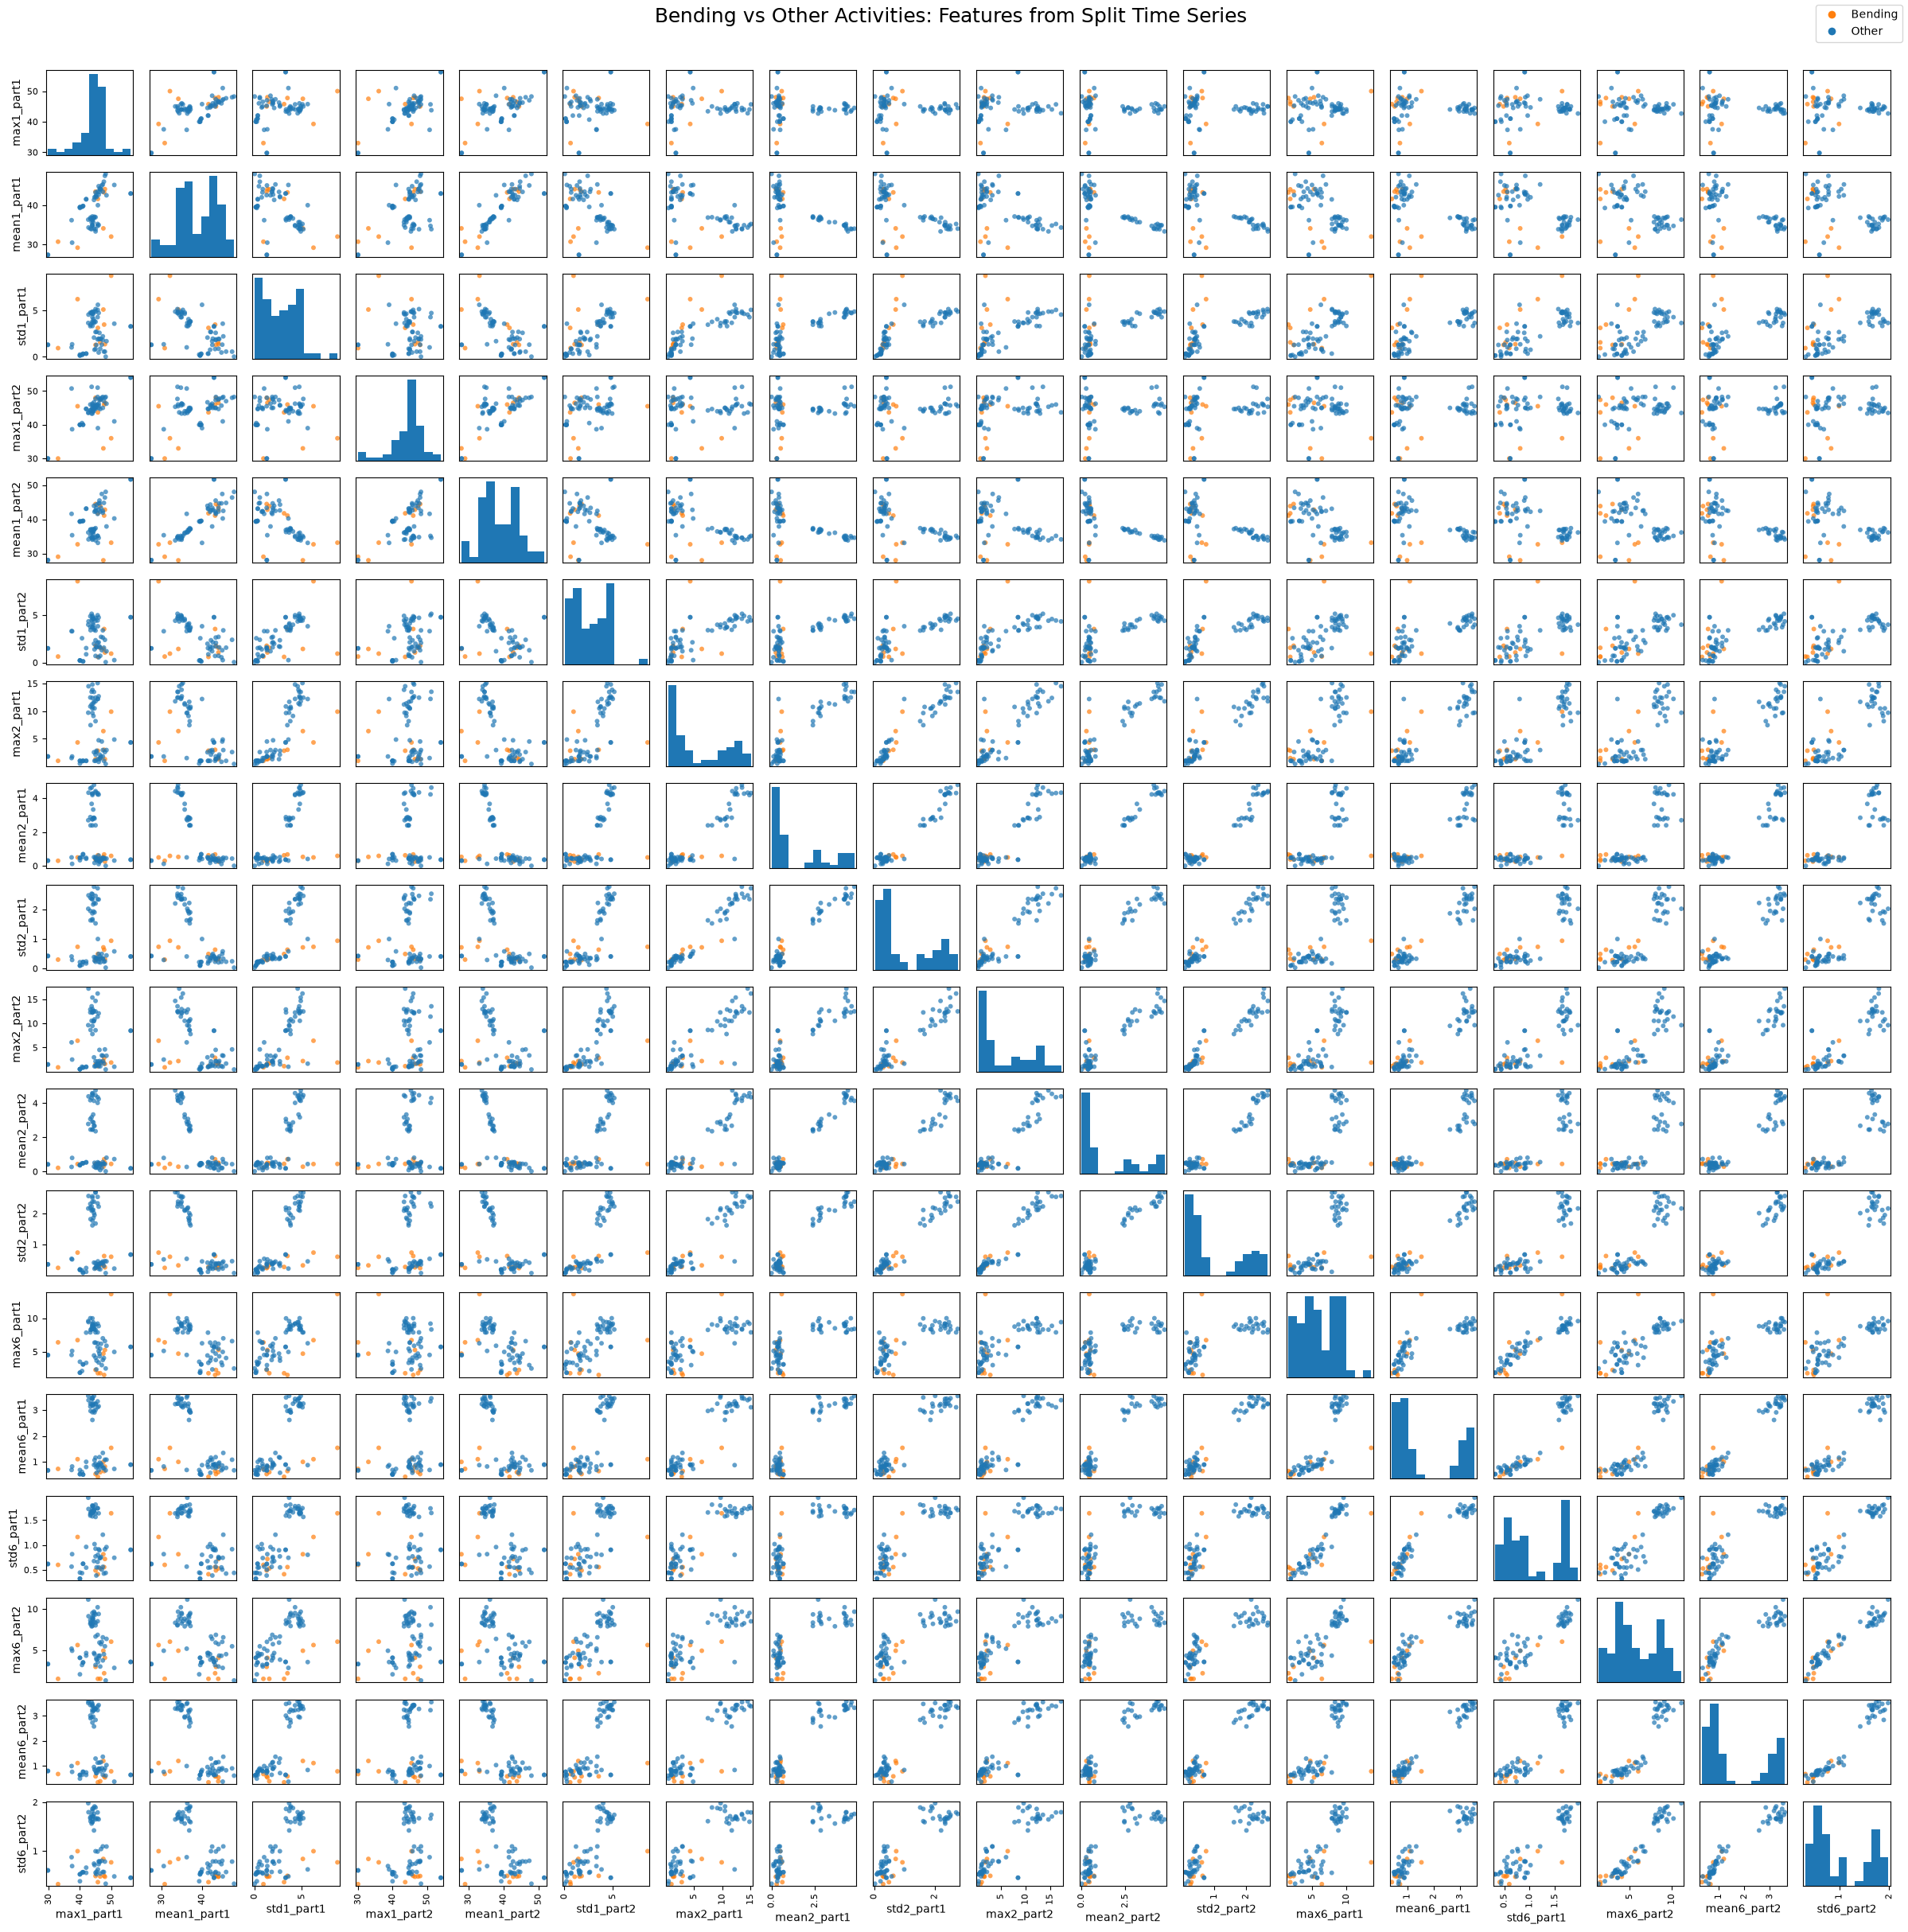

In [6]:
train_files = [
    file for file, is_test in zip(csv_files, full_df["is_test"])
    if not is_test
]


selected_series = [1, 2, 6]
statistics = ["max", "mean", "std"]

feature_rows = []

for file_path in train_files:


    df = pd.read_csv(
        file_path,
        skiprows=5,
        header=None,
        usecols=range(1, 7),
        sep=r",\s*|\s+",
        engine="python"
    )

    df = df.apply(pd.to_numeric, errors="raise")

    row = {}


    for i in selected_series:
        series = df.iloc[:, i - 1].to_numpy()
        halves = np.array_split(series, 2)

        for part_num, part in enumerate(halves, start=1):
            row[f"max{i}_part{part_num}"] = np.max(part)
            row[f"mean{i}_part{part_num}"] = np.mean(part)
            row[f"std{i}_part{part_num}"] = np.std(part, ddof=1)

    feature_rows.append(row)


split_features_df = pd.DataFrame(feature_rows)


split_features_df["class"] = train_df["class"].to_numpy()

print("Training instances:", len(split_features_df))
print("Number of extracted features:", len(split_features_df.columns) - 1)

display(split_features_df.head())


feature_cols = split_features_df.drop(columns=["class"]).columns

colors = split_features_df["class"].map({
    "bending": "tab:orange",
    "other": "tab:blue"
})

axes = scatter_matrix(
    split_features_df[feature_cols],
    figsize=(24, 24),
    diagonal="hist",
    c=colors,
    alpha=0.7,
    marker="o",
    s=18
)


legend = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="tab:orange",
           label="Bending", markersize=8),
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="tab:blue",
           label="Other", markersize=8)
]

fig = axes[0, 0].get_figure()
fig.legend(handles=legend, loc="upper right")

fig.suptitle(
    "Bending vs Other Activities: Features from Split Time Series",
    fontsize=18,
    y=1.01
)

plt.tight_layout()
plt.show()

I do not see any substantial changes in regards to the seperation of bending from other activities. There still exists a lot of overlap. 

2.a.iii.

In [7]:
train_files = [
    file for file, is_test in zip(csv_files, full_df["is_test"])
    if not is_test
]

y_train = (
    train_df["class"]
    .map({"other": 0, "bending": 1})
    .to_numpy()
)


raw_train = []

for file_path in train_files:
    df = pd.read_csv(
        file_path,
        skiprows=5,
        header=None,
        usecols=range(1, 7),
        sep=r",\s*|\s+",
        engine="python"
    )

    df = df.apply(pd.to_numeric, errors="raise")
    raw_train.append(df.to_numpy(dtype=float))

assert len(raw_train) == len(y_train) == 69

def extract_features(recordings, l):
    """
    Split each of the six time series into l approximately
    equal segments and extract seven statistics per segment.
    """
    rows = []

    for recording in recordings:
        features = {}

        for series_idx in range(6):
            series = recording[:, series_idx]
            segments = np.array_split(series, l)

            for segment_idx, segment in enumerate(segments, 1):
                prefix = f"s{series_idx + 1}_seg{segment_idx}"

                features[f"{prefix}_min"] = np.min(segment)
                features[f"{prefix}_max"] = np.max(segment)
                features[f"{prefix}_mean"] = np.mean(segment)
                features[f"{prefix}_median"] = np.median(segment)
                features[f"{prefix}_std"] = np.std(segment, ddof=1)
                features[f"{prefix}_q1"] = np.quantile(segment, 0.25)
                features[f"{prefix}_q3"] = np.quantile(segment, 0.75)

        rows.append(features)

    return pd.DataFrame(rows)


feature_sets = {
    l: extract_features(raw_train, l)
    for l in range(1, 21)
}


for l, X in feature_sets.items():
    print(f"l={l:2d}: {X.shape[0]} instances, "
          f"{X.shape[1]} features")

l= 1: 69 instances, 42 features
l= 2: 69 instances, 84 features
l= 3: 69 instances, 126 features
l= 4: 69 instances, 168 features
l= 5: 69 instances, 210 features
l= 6: 69 instances, 252 features
l= 7: 69 instances, 294 features
l= 8: 69 instances, 336 features
l= 9: 69 instances, 378 features
l=10: 69 instances, 420 features
l=11: 69 instances, 462 features
l=12: 69 instances, 504 features
l=13: 69 instances, 546 features
l=14: 69 instances, 588 features
l=15: 69 instances, 630 features
l=16: 69 instances, 672 features
l=17: 69 instances, 714 features
l=18: 69 instances, 756 features
l=19: 69 instances, 798 features
l=20: 69 instances, 840 features


In [8]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)



lr = LogisticRegression(
    penalty="l2",
    solver="lbfgs",
    max_iter=300,
    random_state=42
)


p_values = list(range(1, 21)) + [25, 30, 40]

cv_results = []
best_models = {}

for l in range(1, 21):

    X = feature_sets[l]



    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("rfe", RFE(
            estimator=LogisticRegression(
                max_iter=300,
                solver="lbfgs",
                random_state=42
            ),
            step=1
        )),
        ("model", LogisticRegression(
            max_iter=300,
            solver="lbfgs",
            random_state=42
        ))
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid={
            "rfe__n_features_to_select": p_values
        },
        scoring="balanced_accuracy",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    grid.fit(X, y_train)


    best_models[l] = grid.best_estimator_

    for p, score in zip(
        grid.cv_results_["param_rfe__n_features_to_select"],
        grid.cv_results_["mean_test_score"]
    ):
        cv_results.append({
            "l": l,
            "p": int(p),
            "CV Balanced Accuracy": score,
            "CV Error": 1 - score
        })

    print(
        f"l={l:2d} | "
        f"Best p={grid.best_params_['rfe__n_features_to_select']:2d} | "
        f"CV Balanced Accuracy={grid.best_score_:.4f}"
    )


cv_results_df = pd.DataFrame(cv_results)



cv_results_df = cv_results_df.sort_values(
    ["CV Balanced Accuracy", "l", "p"],
    ascending=[False, True, True]
).reset_index(drop=True)

best_l = int(cv_results_df.iloc[0]["l"])
best_p = int(cv_results_df.iloc[0]["p"])
best_score = cv_results_df.iloc[0]["CV Balanced Accuracy"]

print("\nBest combination:")
print("l =", best_l)
print("p =", best_p)
print("CV balanced accuracy =", round(best_score, 4))

display(cv_results_df.head(15))

l= 1 | Best p= 9 | CV Balanced Accuracy=0.9500
l= 2 | Best p= 3 | CV Balanced Accuracy=0.8917
l= 3 | Best p=12 | CV Balanced Accuracy=0.9000
l= 4 | Best p= 2 | CV Balanced Accuracy=0.8417
l= 5 | Best p= 1 | CV Balanced Accuracy=0.8500
l= 6 | Best p= 9 | CV Balanced Accuracy=0.8917
l= 7 | Best p=30 | CV Balanced Accuracy=0.8417
l= 8 | Best p=25 | CV Balanced Accuracy=0.8417
l= 9 | Best p= 6 | CV Balanced Accuracy=0.7500
l=10 | Best p=40 | CV Balanced Accuracy=0.7917
l=11 | Best p= 6 | CV Balanced Accuracy=0.8917
l=12 | Best p= 5 | CV Balanced Accuracy=0.9000
l=13 | Best p= 2 | CV Balanced Accuracy=0.8500
l=14 | Best p=19 | CV Balanced Accuracy=0.9000
l=15 | Best p=13 | CV Balanced Accuracy=0.8417
l=16 | Best p=16 | CV Balanced Accuracy=0.8917
l=17 | Best p=18 | CV Balanced Accuracy=0.8917
l=18 | Best p= 1 | CV Balanced Accuracy=0.8500
l=19 | Best p= 1 | CV Balanced Accuracy=0.8500
l=20 | Best p= 7 | CV Balanced Accuracy=0.8917

Best combination:
l = 1
p = 9
CV balanced accuracy = 0.95


,l,p,CV Balanced Accuracy,CV Error
0,1,9,0.950000,0.050000
1,1,6,0.900000,0.100000
2,1,7,0.900000,0.100000
3,3,12,0.900000,0.100000
4,3,20,0.900000,0.100000
5,12,5,0.900000,0.100000
6,12,6,0.900000,0.100000
7,14,19,0.900000,0.100000
8,14,20,0.900000,0.100000
9,2,3,0.891667,0.108333


In [9]:
pvalue_results = []

for l in range(1, 21):
    X = feature_sets[l]
    pipeline = best_models[l]


    mask = pipeline.named_steps["rfe"].support_
    selected_names = X.columns[mask]


    X_scaled = pipeline.named_steps["scaler"].transform(X)

    X_selected = pd.DataFrame(
        X_scaled[:, mask],
        columns=selected_names
    )


    X_sm = sm.add_constant(
        X_selected,
        has_constant="add"
    )

    try:

        with warnings.catch_warnings():
            warnings.simplefilter("error")
            model = sm.GLM(
                y_train,
                X_sm,
                family=sm.families.Binomial()
            ).fit(maxiter=200)

        if not model.converged:
            raise RuntimeError("GLM did not converge")

        for feature in X_sm.columns:
            pvalue_results.append({
                "l": l,
                "Feature": feature,
                "Coefficient": model.params[feature],
                "P-Value": model.pvalues[feature]
            })

    except (Exception) as e:
        print(f"l={l}: p-values unavailable ({e})")

pvalue_df = pd.DataFrame(pvalue_results)


if not pvalue_df.empty:
    best_model_pvalues = pvalue_df[
        pvalue_df["l"] == best_l
    ].sort_values("P-Value")

    display(best_model_pvalues)

l=1: p-values unavailable (Perfect separation or prediction detected, parameter may not be identified)
l=3: p-values unavailable (Perfect separation or prediction detected, parameter may not be identified)
l=6: p-values unavailable (Perfect separation or prediction detected, parameter may not be identified)
l=7: p-values unavailable (Perfect separation or prediction detected, parameter may not be identified)
l=8: p-values unavailable (Perfect separation or prediction detected, parameter may not be identified)
l=9: p-values unavailable (Perfect separation or prediction detected, parameter may not be identified)
l=10: p-values unavailable (Perfect separation or prediction detected, parameter may not be identified)
l=11: p-values unavailable (Perfect separation or prediction detected, parameter may not be identified)
l=12: p-values unavailable (Perfect separation or prediction detected, parameter may not be identified)
l=14: p-values unavailable (Perfect separation or prediction detected,

,l,Feature,Coefficient,P-Value


The best (l,p) appears to be the best with a cv accuracy of 95%. 

The right way to do CV: For each of the five folds, fit the scaler and RFE on only the four training folds, fit logistic regression using those selected features, and evaluate predictions on the remaining validation fold. Repeat for every candidate (l,p) and select the best combination based on average validation performance.

The wrong way to do CV: Select features using all 69 training instances, then perform cross-validation on that already-pruned dataset. This can result in leaking. 

2.a.iv.

ROC and AUC:

Training Confusion Matrix:
[[60  0]
 [ 0  9]]

Training Accuracy: 1.0


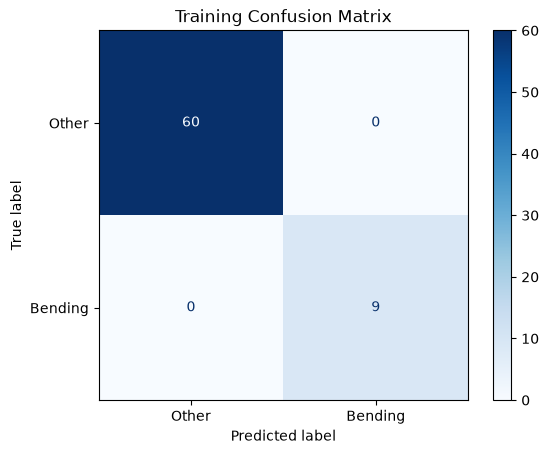

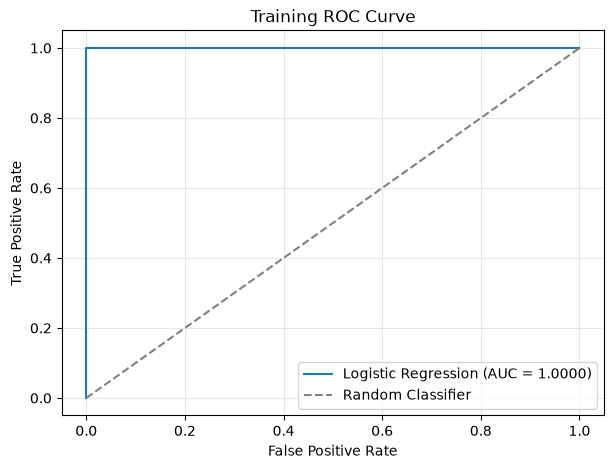

Training AUC: 1.0


In [10]:
best_model = best_models[best_l]


X_train_best = feature_sets[best_l]


y_train_pred = best_model.predict(X_train_best)


y_train_prob = best_model.predict_proba(X_train_best)[:, 1]


cm = confusion_matrix(y_train, y_train_pred)

print("Training Confusion Matrix:")
print(cm)

print("\nTraining Accuracy:",
      accuracy_score(y_train, y_train_pred))


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Other", "Bending"]
)

disp.plot(cmap="Blues")
plt.title("Training Confusion Matrix")
plt.show()


fpr, tpr, thresholds = roc_curve(y_train, y_train_prob)
auc_score = roc_auc_score(y_train, y_train_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr, tpr,
    label=f"Logistic Regression (AUC = {auc_score:.4f})"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Training ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

print("Training AUC:", auc_score)

parameters:

In [11]:
selected_mask = best_model.named_steps["rfe"].support_
selected_features = X_train_best.columns[selected_mask]


coefficients = best_model.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient (Beta)": coefficients
})

print("Intercept:",
      best_model.named_steps["model"].intercept_[0])

display(coef_df)

Intercept: -3.9267516436836396


,Feature,Coefficient (Beta)
0,s1_seg1_mean,-0.466090
1,s1_seg1_q3,-0.660721
2,s2_seg1_q3,-0.483946
3,s5_seg1_min,0.767212
4,s5_seg1_max,1.367194
5,s5_seg1_mean,0.691965
6,s5_seg1_q1,0.615809
7,s6_seg1_median,-0.515490
8,s6_seg1_q1,-0.555611


2.a.v.

In [12]:
best_model = best_models[best_l]


test_files = [
    file for file, is_test in zip(csv_files, full_df["is_test"])
    if is_test
]


raw_test = []

for file_path in test_files:
    df = pd.read_csv(
        file_path,
        skiprows=5,
        header=None,
        usecols=range(1, 7),
        sep=r",\s*|\s+",
        engine="python"
    )

    df = df.apply(pd.to_numeric, errors="raise")
    raw_test.append(df.to_numpy(dtype=float))


X_test = extract_features(raw_test, best_l)


y_test = (
    test_df["class"]
    .map({"other": 0, "bending": 1})
    .to_numpy()
)


assert list(X_test.columns) == list(feature_sets[best_l].columns)
assert len(X_test) == len(y_test) == 19


y_test_pred = best_model.predict(X_test)


test_accuracy = accuracy_score(y_test, y_test_pred)
test_balanced_accuracy = balanced_accuracy_score(
    y_test, y_test_pred
)


cv_balanced_accuracy = best_score

print(f"Optimal l: {best_l}")
print(f"Optimal p: {best_p}")

print(f"\nCV Balanced Accuracy: {cv_balanced_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Balanced Accuracy: {test_balanced_accuracy:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Other", "Bending"],
    zero_division=0
))

print(
    "\nDifference in balanced accuracy: "
    f"{test_balanced_accuracy - cv_balanced_accuracy:+.4f}"
)

Optimal l: 1
Optimal p: 9

CV Balanced Accuracy: 0.9500
Test Accuracy: 1.0000
Test Balanced Accuracy: 1.0000

Confusion Matrix:
[[15  0]
 [ 0  4]]

Classification Report:
              precision    recall  f1-score   support

       Other       1.00      1.00      1.00        15
     Bending       1.00      1.00      1.00         4

    accuracy                           1.00        19
   macro avg       1.00      1.00      1.00        19
weighted avg       1.00      1.00      1.00        19


Difference in balanced accuracy: +0.0500


2.a.vi.

Yes. The bending and non-bending classes appear to be sufficiently well separated in the selected feature space to cause instability when estimating logistic regression coefficients.

2.a.vii.

Yes. My confusion matrices and class distributions indicate a substantial class imbalance

Selected features: 9
Original class distribution:
0    60
1     9
Name: count, dtype: int64

Case-control sample distribution:
0    9
1    9
Name: count, dtype: int64

Original intercept: 0.2697679304025405
Adjusted intercept: -1.6273520544833409
Correction: -1.8971199848858813

Case-Control Logistic Regression Results
Accuracy: 0.9565
Balanced Accuracy: 0.8333
AUC: 1.0

Confusion Matrix:
[[60  0]
 [ 3  6]]

Classification Report:
              precision    recall  f1-score   support

       Other       0.95      1.00      0.98        60
     Bending       1.00      0.67      0.80         9

    accuracy                           0.96        69
   macro avg       0.98      0.83      0.89        69
weighted avg       0.96      0.96      0.95        69



c:\Users\eddy0\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


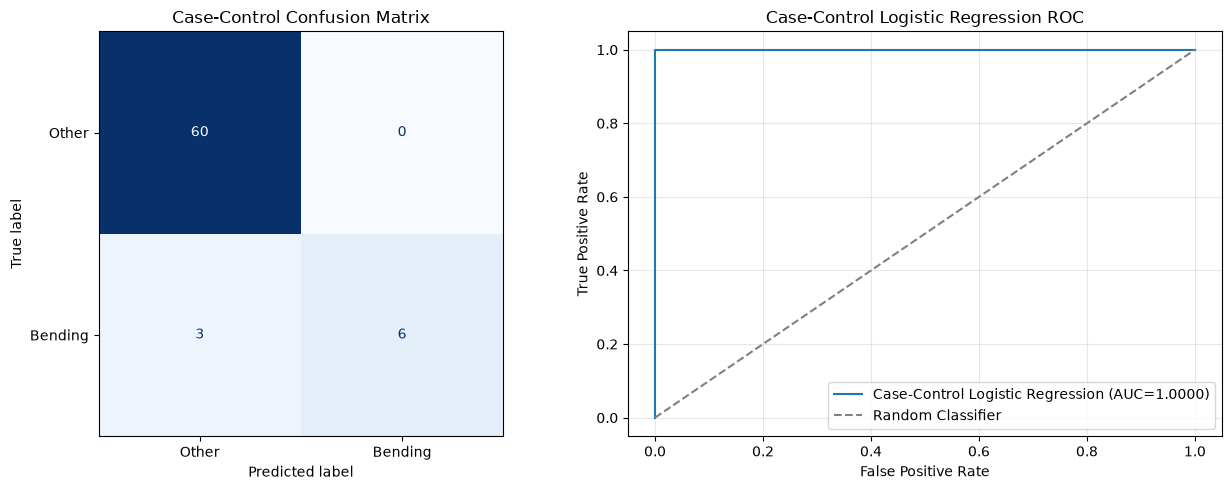


Adjusted Intercept: -1.6273520544833409


,Feature,Coefficient
0,s1_seg1_mean,-0.320329
1,s1_seg1_q3,-0.371289
2,s2_seg1_q3,-0.474490
3,s5_seg1_min,0.457693
4,s5_seg1_max,1.036465
5,s5_seg1_mean,0.670647
6,s5_seg1_q1,0.664933
7,s6_seg1_median,-0.525102
8,s6_seg1_q1,-0.506799


In [13]:
X_train = feature_sets[best_l]

best_model = best_models[best_l]

selected_mask = best_model.named_steps["rfe"].support_
selected_features = X_train.columns[selected_mask]

X_selected = X_train[selected_features]

print("Selected features:", len(selected_features))
print("Original class distribution:")
print(pd.Series(y_train).value_counts().sort_index())





rng = np.random.default_rng(42)


bending_idx = np.where(y_train == 1)[0]
other_idx = np.where(y_train == 0)[0]



sampled_other_idx = rng.choice(
    other_idx,
    size=len(bending_idx),
    replace=False
)

sampled_idx = np.concatenate([
    bending_idx,
    sampled_other_idx
])

rng.shuffle(sampled_idx)

X_sampled = X_selected.iloc[sampled_idx]
y_sampled = y_train[sampled_idx]

print("\nCase-control sample distribution:")
print(pd.Series(y_sampled).value_counts().sort_index())





cc_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        penalty="l2",
        solver="lbfgs",
        max_iter=300,
        random_state=42
    ))
])

cc_model.fit(X_sampled, y_sampled)






pi_original = np.mean(y_train)


pi_sampled = np.mean(y_sampled)


correction = (
    logit(pi_original) - logit(pi_sampled)
)

logistic = cc_model.named_steps["logistic"]

original_intercept = logistic.intercept_[0]
adjusted_intercept = original_intercept + correction

print("\nOriginal intercept:", original_intercept)
print("Adjusted intercept:", adjusted_intercept)
print("Correction:", correction)






scores = cc_model.decision_function(X_selected)


adjusted_scores = scores + correction
y_prob = expit(adjusted_scores)


y_pred = (y_prob >= 0.5).astype(int)





cm = confusion_matrix(y_train, y_pred)

accuracy = accuracy_score(y_train, y_pred)
balanced_accuracy = balanced_accuracy_score(
    y_train, y_pred
)
auc_score = roc_auc_score(y_train, y_prob)

print("\nCase-Control Logistic Regression Results")
print("Accuracy:", round(accuracy, 4))
print("Balanced Accuracy:", round(balanced_accuracy, 4))
print("AUC:", round(auc_score, 4))

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_train,
    y_pred,
    target_names=["Other", "Bending"],
    zero_division=0
))





fig, axes = plt.subplots(1, 2, figsize=(13, 5))


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Other", "Bending"]
)

disp.plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Case-Control Confusion Matrix")


fpr, tpr, thresholds = roc_curve(
    y_train, y_prob
)

axes[1].plot(
    fpr, tpr,
    label=f"Case-Control Logistic Regression (AUC={auc_score:.4f})"
)

axes[1].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Case-Control Logistic Regression ROC")
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()





parameter_df = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": logistic.coef_[0]
})

print("\nAdjusted Intercept:", adjusted_intercept)
display(parameter_df)

2.b.i

In [14]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


C_values = np.logspace(-3, 3, 15)


l1_results = []
l1_best_models = {}


for l in range(1, 21):

    X = feature_sets[l]

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            l1_ratio=1.0,
            solver="liblinear",
            max_iter=2000,
            random_state=42
        ))
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid={"model__C": C_values},
        scoring="balanced_accuracy",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    grid.fit(X, y_train)

    l1_best_models[l] = grid.best_estimator_

    for C, score in zip(
        grid.cv_results_["param_model__C"],
        grid.cv_results_["mean_test_score"]
    ):
        l1_results.append({
            "l": l,
            "C": float(C),
            "CV Balanced Accuracy": score,
            "CV Error": 1 - score
        })

    print(
        f"l={l:2d} | "
        f"Best C={grid.best_params_['model__C']:.5f} | "
        f"CV Balanced Accuracy={grid.best_score_:.4f}"
    )


l1_results_df = pd.DataFrame(l1_results)

l1_results_df = l1_results_df.sort_values(
    ["CV Balanced Accuracy", "l", "C"],
    ascending=[False, True, True]
).reset_index(drop=True)

best_l_l1 = int(l1_results_df.iloc[0]["l"])
best_C_l1 = float(l1_results_df.iloc[0]["C"])
best_score_l1 = float(
    l1_results_df.iloc[0]["CV Balanced Accuracy"]
)

print("\nOptimal L1 Logistic Regression:")
print("Best l:", best_l_l1)
print("Best C:", best_C_l1)
print("Best CV balanced accuracy:", round(best_score_l1, 4))

display(l1_results_df.head(15))

l= 1 | Best C=1000.00000 | CV Balanced Accuracy=0.9833
l= 2 | Best C=19.30698 | CV Balanced Accuracy=0.9333
l= 3 | Best C=1.00000 | CV Balanced Accuracy=0.8917
l= 4 | Best C=51.79475 | CV Balanced Accuracy=0.8833
l= 5 | Best C=19.30698 | CV Balanced Accuracy=0.7917
l= 6 | Best C=19.30698 | CV Balanced Accuracy=0.9333
l= 7 | Best C=51.79475 | CV Balanced Accuracy=0.8417
l= 8 | Best C=51.79475 | CV Balanced Accuracy=0.8500
l= 9 | Best C=2.68270 | CV Balanced Accuracy=0.7917
l=10 | Best C=138.94955 | CV Balanced Accuracy=0.9417
l=11 | Best C=1.00000 | CV Balanced Accuracy=0.8917
l=12 | Best C=1.00000 | CV Balanced Accuracy=0.9417
l=13 | Best C=19.30698 | CV Balanced Accuracy=0.9417
l=14 | Best C=138.94955 | CV Balanced Accuracy=0.9333
l=15 | Best C=372.75937 | CV Balanced Accuracy=0.8417
l=16 | Best C=138.94955 | CV Balanced Accuracy=0.8833
l=17 | Best C=51.79475 | CV Balanced Accuracy=0.8917
l=18 | Best C=1.00000 | CV Balanced Accuracy=0.8917
l=19 | Best C=1.00000 | CV Balanced Accuracy=

,l,C,CV Balanced Accuracy,CV Error
0,1,1000.000000,0.983333,0.016667
1,1,2.682696,0.950000,0.050000
2,10,138.949549,0.941667,0.058333
3,10,372.759372,0.941667,0.058333
4,12,1.000000,0.941667,0.058333
5,12,2.682696,0.941667,0.058333
6,12,7.196857,0.941667,0.058333
7,12,19.306977,0.941667,0.058333
8,13,19.306977,0.941667,0.058333
9,20,19.306977,0.941667,0.058333


In [15]:
best_l1_model = l1_best_models[best_l_l1]


X_train_l1 = feature_sets[best_l_l1]


coefficients = best_l1_model.named_steps["model"].coef_[0]
intercept = best_l1_model.named_steps["model"].intercept_[0]


nonzero_mask = np.abs(coefficients) > 1e-6

selected_features_l1 = X_train_l1.columns[nonzero_mask]


l1_coef_df = pd.DataFrame({
    "Feature": X_train_l1.columns,
    "Coefficient": coefficients,
    "Selected": nonzero_mask
})

print("Best l:", best_l_l1)
print("Best C:", best_C_l1)
print("Total available features:", X_train_l1.shape[1])
print("Number of selected features:", nonzero_mask.sum())
print("Intercept:", intercept)

print("\nSelected features and coefficients:")
display(
    l1_coef_df[l1_coef_df["Selected"]]
    .sort_values("Coefficient", key=abs, ascending=False)
)

Best l: 1
Best C: 1000.0
Total available features: 42
Number of selected features: 17
Intercept: -11.322457445767592

Selected features and coefficients:


,Feature,Coefficient,Selected
28,s5_seg1_min,6.093444,True
29,s5_seg1_max,5.350524,True
6,s1_seg1_q3,-2.838671,True
8,s2_seg1_max,-2.221635,True
0,s1_seg1_min,-2.101506,True
40,s6_seg1_q1,-1.916088,True
22,s4_seg1_max,1.632029,True
26,s4_seg1_q1,-1.481749,True
30,s5_seg1_mean,1.480701,True
20,s3_seg1_q3,-0.952839,True


L1 Logistic Regression - Training Results
Accuracy: 1.0000
Balanced Accuracy: 1.0000
AUC: 1.0000

Classification Report:
              precision    recall  f1-score   support

       Other       1.00      1.00      1.00        60
     Bending       1.00      1.00      1.00         9

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



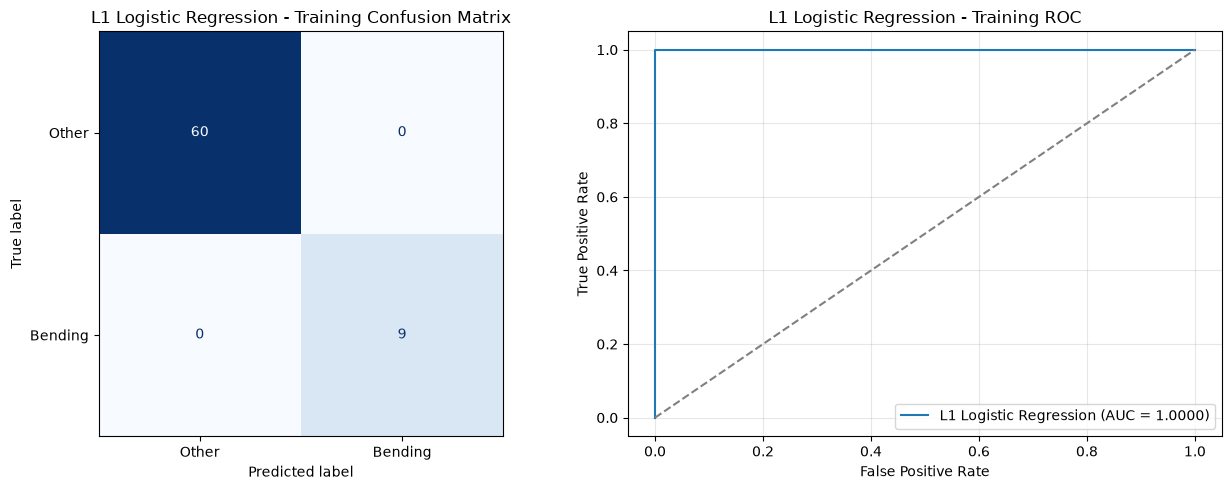

In [16]:
y_train_pred_l1 = best_l1_model.predict(X_train_l1)
y_train_prob_l1 = best_l1_model.predict_proba(X_train_l1)[:, 1]


train_accuracy_l1 = accuracy_score(
    y_train, y_train_pred_l1
)

train_balanced_accuracy_l1 = balanced_accuracy_score(
    y_train, y_train_pred_l1
)

train_auc_l1 = roc_auc_score(
    y_train, y_train_prob_l1
)

print("L1 Logistic Regression - Training Results")
print(f"Accuracy: {train_accuracy_l1:.4f}")
print(f"Balanced Accuracy: {train_balanced_accuracy_l1:.4f}")
print(f"AUC: {train_auc_l1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_train,
    y_train_pred_l1,
    target_names=["Other", "Bending"],
    zero_division=0
))


cm = confusion_matrix(y_train, y_train_pred_l1)


fpr, tpr, thresholds = roc_curve(
    y_train, y_train_prob_l1
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Other", "Bending"]
)

disp.plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)
axes[0].set_title("L1 Logistic Regression - Training Confusion Matrix")


axes[1].plot(
    fpr, tpr,
    label=f"L1 Logistic Regression (AUC = {train_auc_l1:.4f})"
)

axes[1].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray"
)

axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("L1 Logistic Regression - Training ROC")
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Evaluating on test set:

In [17]:
X_test_l1 = extract_features(raw_test, best_l_l1)


assert list(X_test_l1.columns) == list(X_train_l1.columns)


y_test_pred_l1 = best_l1_model.predict(X_test_l1)
y_test_prob_l1 = best_l1_model.predict_proba(X_test_l1)[:, 1]


test_accuracy_l1 = accuracy_score(
    y_test, y_test_pred_l1
)

test_balanced_accuracy_l1 = balanced_accuracy_score(
    y_test, y_test_pred_l1
)

test_auc_l1 = roc_auc_score(
    y_test, y_test_prob_l1
)

print("L1 Logistic Regression - Test Results")
print(f"Accuracy: {test_accuracy_l1:.4f}")
print(f"Balanced Accuracy: {test_balanced_accuracy_l1:.4f}")
print(f"AUC: {test_auc_l1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_l1))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_l1,
    target_names=["Other", "Bending"],
    zero_division=0
))

L1 Logistic Regression - Test Results
Accuracy: 1.0000
Balanced Accuracy: 1.0000
AUC: 1.0000

Confusion Matrix:
[[15  0]
 [ 0  4]]

Classification Report:
              precision    recall  f1-score   support

       Other       1.00      1.00      1.00        15
     Bending       1.00      1.00      1.00         4

    accuracy                           1.00        19
   macro avg       1.00      1.00      1.00        19
weighted avg       1.00      1.00      1.00        19



As seen above, the best combination is (l,C) = (1,1000)

2.b.ii.

L1 regularization achieved better cross-validation performance (98.33% versus 95%), while both methods achieved identical test accuracy. I feel L1 is also generally easier to implement than RFE.

2.c.i

test and labels

In [18]:
activity_classes = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking"
]


y_train_multi = train_df["activity"].to_numpy()
y_test_multi = test_df["activity"].to_numpy()

print("Training distribution:")
print(pd.Series(y_train_multi).value_counts().sort_index())

print("\nTest distribution:")
print(pd.Series(y_test_multi).value_counts().sort_index())

print("\nTotal training instances:", len(y_train_multi))
print("Total test instances:", len(y_test_multi))

Training distribution:
bending1     5
bending2     4
cycling     12
lying       12
sitting     12
standing    12
walking     12
Name: count, dtype: int64

Test distribution:
bending1    2
bending2    2
cycling     3
lying       3
sitting     3
standing    3
walking     3
Name: count, dtype: int64

Total training instances: 69
Total test instances: 19


best I and C (using 4 folds instead)

In [19]:
cv_multi = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)


C_values_multi = np.logspace(-3, 3, 15)

multi_results = []
multi_best_models = {}

for l in range(1, 21):

    X = feature_sets[l]

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            l1_ratio=1.0,
            solver="saga",
            max_iter=5000,
            tol=1e-3,
            random_state=42
        ))
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid={"model__C": C_values_multi},
        scoring="balanced_accuracy",
        cv=cv_multi,
        n_jobs=-1,
        error_score="raise",
        refit=True
    )

    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            category=ConvergenceWarning
        )
        grid.fit(X, y_train_multi)

    multi_best_models[l] = grid.best_estimator_

    for C, score in zip(
        grid.cv_results_["param_model__C"],
        grid.cv_results_["mean_test_score"]
    ):
        multi_results.append({
            "l": l,
            "C": float(C),
            "CV Balanced Accuracy": float(score),
            "CV Error": 1 - float(score)
        })

    print(
        f"l={l:2d} | "
        f"Best C={grid.best_params_['model__C']:.5f} | "
        f"CV Balanced Accuracy={grid.best_score_:.4f}"
    )


multi_results_df = pd.DataFrame(multi_results)


assert multi_results_df["CV Balanced Accuracy"].notna().all(), (
    "Some cross-validation scores are NaN."
)

multi_results_df = multi_results_df.sort_values(
    ["CV Balanced Accuracy", "l", "C"],
    ascending=[False, True, True]
).reset_index(drop=True)


best_l_multi = int(multi_results_df.iloc[0]["l"])
best_C_multi = float(multi_results_df.iloc[0]["C"])
best_cv_multi = float(
    multi_results_df.iloc[0]["CV Balanced Accuracy"]
)

best_multi_model = multi_best_models[best_l_multi]

print("\nOptimal Multinomial L1 Logistic Regression")
print("Best l:", best_l_multi)
print("Best C:", best_C_multi)
print("Best CV balanced accuracy:", round(best_cv_multi, 4))

display(multi_results_df.head(15))

l= 1 | Best C=2.68270 | CV Balanced Accuracy=0.8810
l= 2 | Best C=138.94955 | CV Balanced Accuracy=0.8571
l= 3 | Best C=19.30698 | CV Balanced Accuracy=0.8214
l= 4 | Best C=19.30698 | CV Balanced Accuracy=0.8095
l= 5 | Best C=51.79475 | CV Balanced Accuracy=0.8333
l= 6 | Best C=19.30698 | CV Balanced Accuracy=0.8452
l= 7 | Best C=2.68270 | CV Balanced Accuracy=0.8095
l= 8 | Best C=19.30698 | CV Balanced Accuracy=0.8452
l= 9 | Best C=7.19686 | CV Balanced Accuracy=0.8452
l=10 | Best C=51.79475 | CV Balanced Accuracy=0.8214
l=11 | Best C=0.37276 | CV Balanced Accuracy=0.7083
l=12 | Best C=138.94955 | CV Balanced Accuracy=0.8036
l=13 | Best C=19.30698 | CV Balanced Accuracy=0.8036
l=14 | Best C=19.30698 | CV Balanced Accuracy=0.7917
l=15 | Best C=19.30698 | CV Balanced Accuracy=0.8452
l=16 | Best C=19.30698 | CV Balanced Accuracy=0.7798
l=17 | Best C=19.30698 | CV Balanced Accuracy=0.8036
l=18 | Best C=7.19686 | CV Balanced Accuracy=0.8571
l=19 | Best C=1000.00000 | CV Balanced Accuracy=0

,l,C,CV Balanced Accuracy,CV Error
0,1,2.682696,0.880952,0.119048
1,2,138.949549,0.857143,0.142857
2,2,372.759372,0.857143,0.142857
3,2,1000.000000,0.857143,0.142857
4,18,7.196857,0.857143,0.142857
5,1,7.196857,0.845238,0.154762
6,1,19.306977,0.845238,0.154762
7,1,51.794747,0.845238,0.154762
8,1,138.949549,0.845238,0.154762
9,1,372.759372,0.845238,0.154762


multiclass confusion matrix

In [20]:
best_multi_model = multi_best_models[best_l_multi]


X_test_multi = extract_features(raw_test, best_l_multi)


y_test_multi = test_df["activity"].to_numpy()


y_pred_multi = best_multi_model.predict(X_test_multi)


y_prob_multi = best_multi_model.predict_proba(X_test_multi)

print("Actual labels:", y_test_multi)
print("Predicted labels:", y_pred_multi)

print("\nTest Accuracy:",
      accuracy_score(y_test_multi, y_pred_multi))

print("Test Error:",
      1 - accuracy_score(y_test_multi, y_pred_multi))

Actual labels: ['bending1' 'bending1' 'bending2' 'bending2' 'cycling' 'cycling' 'cycling'
 'lying' 'lying' 'lying' 'sitting' 'sitting' 'sitting' 'standing'
 'standing' 'standing' 'walking' 'walking' 'walking']
Predicted labels: ['bending1' 'bending1' 'bending2' 'bending2' 'cycling' 'cycling' 'cycling'
 'lying' 'lying' 'lying' 'sitting' 'sitting' 'standing' 'lying' 'standing'
 'standing' 'walking' 'walking' 'walking']

Test Accuracy: 0.8947368421052632
Test Error: 0.10526315789473684


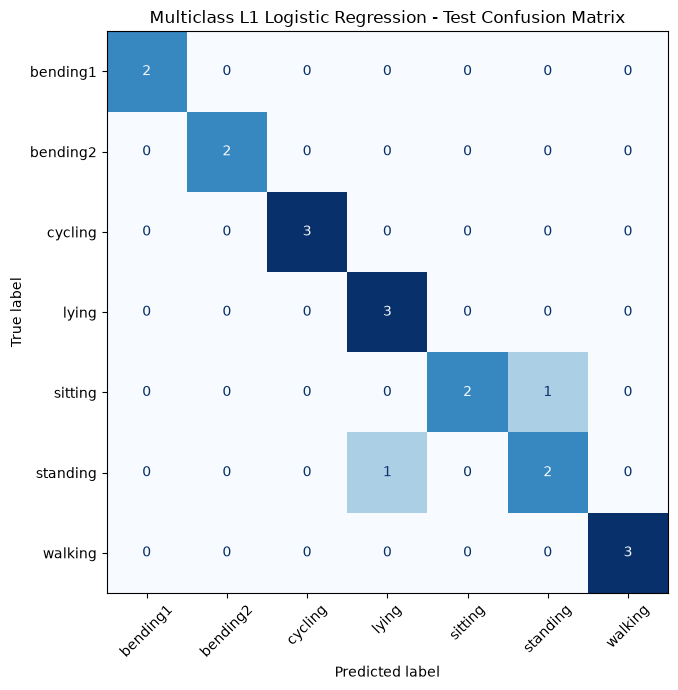

In [21]:
cm_multi = confusion_matrix(
    y_test_multi,
    y_pred_multi,
    labels=activity_classes
)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_multi,
    display_labels=activity_classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

plt.title("Multiclass L1 Logistic Regression - Test Confusion Matrix")
plt.tight_layout()
plt.show()

ROC curves and calculate AUC

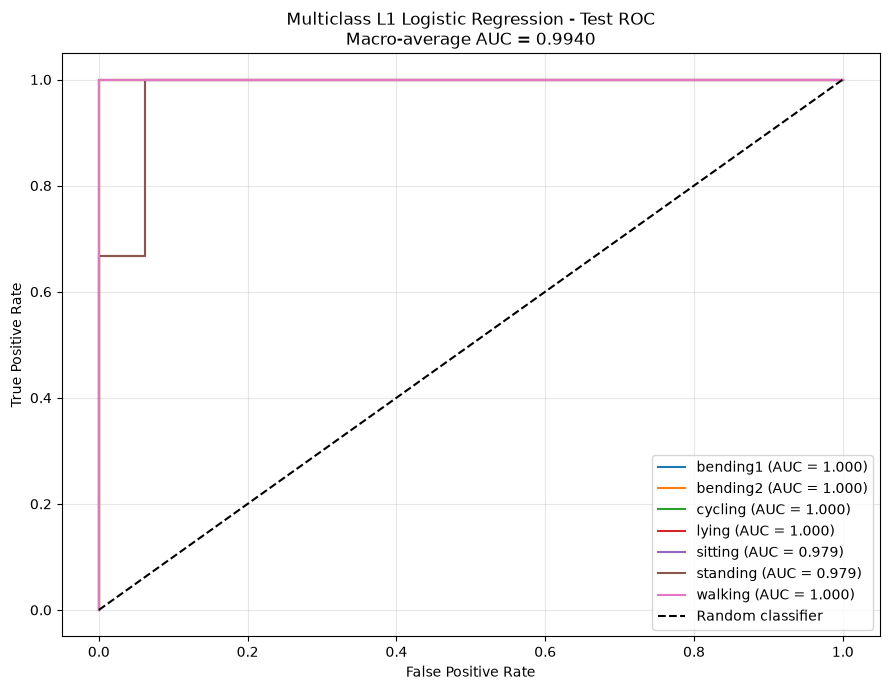

One-vs-Rest AUC Scores:
bending1: 1.0000
bending2: 1.0000
cycling: 1.0000
lying: 1.0000
sitting: 0.9792
standing: 0.9792
walking: 1.0000

Macro-average AUC: 0.994


In [22]:
model_classes = best_multi_model.named_steps["model"].classes_


y_test_binary = label_binarize(
    y_test_multi,
    classes=model_classes
)


fpr_multi = {}
tpr_multi = {}
auc_multi = {}

plt.figure(figsize=(9, 7))


for i, activity in enumerate(model_classes):

    fpr_multi[activity], tpr_multi[activity], _ = roc_curve(
        y_test_binary[:, i],
        y_prob_multi[:, i]
    )

    auc_multi[activity] = auc(
        fpr_multi[activity],
        tpr_multi[activity]
    )

    plt.plot(
        fpr_multi[activity],
        tpr_multi[activity],
        label=f"{activity} (AUC = {auc_multi[activity]:.3f})"
    )


macro_auc_multi = np.mean(list(auc_multi.values()))


plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(
    f"Multiclass L1 Logistic Regression - Test ROC\n"
    f"Macro-average AUC = {macro_auc_multi:.4f}"
)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("One-vs-Rest AUC Scores:")
for activity, score in auc_multi.items():
    print(f"{activity}: {score:.4f}")

print("\nMacro-average AUC:", round(macro_auc_multi, 4))

Visualize cross-validation performance across l

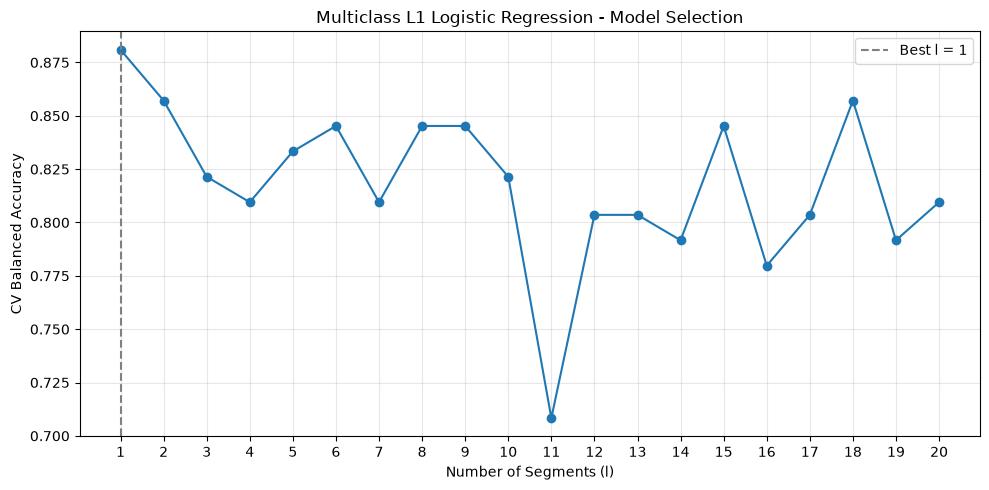

In [23]:
best_by_l = (
    multi_results_df
    .groupby("l")["CV Balanced Accuracy"]
    .max()
    .sort_index()
)

plt.figure(figsize=(10, 5))

plt.plot(
    best_by_l.index,
    best_by_l.values,
    marker="o"
)

plt.axvline(
    best_l_multi,
    linestyle="--",
    color="gray",
    label=f"Best l = {best_l_multi}"
)

plt.xlabel("Number of Segments (l)")
plt.ylabel("CV Balanced Accuracy")
plt.title("Multiclass L1 Logistic Regression - Model Selection")
plt.xticks(range(1, 21))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

2.c.ii

Best I for Gaussian Naive Bayes

In [24]:
cv_nb = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)


gaussian_results = []
gaussian_best_models = {}

for l in range(1, 21):

    X = feature_sets[l]

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", GaussianNB())
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid={
            "model__var_smoothing": np.logspace(-12, -1, 12)
        },
        scoring="balanced_accuracy",
        cv=cv_nb,
        n_jobs=-1,
        error_score="raise",
        refit=True
    )

    grid.fit(X, y_train_multi)
    gaussian_best_models[l] = grid.best_estimator_

    for smoothing, score in zip(
        grid.cv_results_["param_model__var_smoothing"],
        grid.cv_results_["mean_test_score"]
    ):
        gaussian_results.append({
            "l": l,
            "var_smoothing": float(smoothing),
            "CV Balanced Accuracy": float(score)
        })

    print(
        f"l={l:2d} | "
        f"Best smoothing={grid.best_params_['model__var_smoothing']:.2e} | "
        f"CV Balanced Accuracy={grid.best_score_:.4f}"
    )

gaussian_results_df = pd.DataFrame(gaussian_results)

gaussian_results_df = gaussian_results_df.sort_values(
    ["CV Balanced Accuracy", "l", "var_smoothing"],
    ascending=[False, True, True]
).reset_index(drop=True)

best_l_gaussian = int(gaussian_results_df.iloc[0]["l"])
best_smoothing_gaussian = float(
    gaussian_results_df.iloc[0]["var_smoothing"]
)
best_cv_gaussian = float(
    gaussian_results_df.iloc[0]["CV Balanced Accuracy"]
)

best_gaussian_model = gaussian_best_models[best_l_gaussian]

print("\nOptimal Gaussian Naive Bayes")
print("Best l:", best_l_gaussian)
print("Best variance smoothing:", best_smoothing_gaussian)
print("Best CV balanced accuracy:", round(best_cv_gaussian, 4))

display(gaussian_results_df.head(10))

l= 1 | Best smoothing=1.00e-01 | CV Balanced Accuracy=0.8929
l= 2 | Best smoothing=1.00e-01 | CV Balanced Accuracy=0.8810
l= 3 | Best smoothing=1.00e-01 | CV Balanced Accuracy=0.8095
l= 4 | Best smoothing=1.00e-01 | CV Balanced Accuracy=0.8333
l= 5 | Best smoothing=1.00e-01 | CV Balanced Accuracy=0.8095
l= 6 | Best smoothing=1.00e-01 | CV Balanced Accuracy=0.8690
l= 7 | Best smoothing=1.00e-01 | CV Balanced Accuracy=0.8095
l= 8 | Best smoothing=1.00e-01 | CV Balanced Accuracy=0.8571
l= 9 | Best smoothing=1.00e-01 | CV Balanced Accuracy=0.7917
l=10 | Best smoothing=1.00e-01 | CV Balanced Accuracy=0.7440
l=11 | Best smoothing=1.00e-02 | CV Balanced Accuracy=0.7798
l=12 | Best smoothing=1.00e-01 | CV Balanced Accuracy=0.7917
l=13 | Best smoothing=1.00e-01 | CV Balanced Accuracy=0.8095
l=14 | Best smoothing=1.00e-01 | CV Balanced Accuracy=0.8214
l=15 | Best smoothing=1.00e-01 | CV Balanced Accuracy=0.7857
l=16 | Best smoothing=1.00e-01 | CV Balanced Accuracy=0.7857
l=17 | Best smoothing=1.

,l,var_smoothing,CV Balanced Accuracy
0,1,1.000000e-01,0.892857
1,2,1.000000e-01,0.880952
2,6,1.000000e-01,0.869048
3,1,1.000000e-02,0.863095
4,8,1.000000e-01,0.857143
5,4,1.000000e-01,0.833333
6,2,1.000000e-02,0.827381
7,14,1.000000e-01,0.821429
8,1,1.000000e-07,0.815476
9,1,1.000000e-06,0.815476


Multinomial Naive Bayes and find the best l

In [25]:
multinomial_results = []
multinomial_best_models = {}

for l in range(1, 21):

    X = feature_sets[l]

    pipeline = Pipeline([
        ("scaler", MinMaxScaler()),
        ("model", MultinomialNB())
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid={
            "model__alpha": np.logspace(-3, 2, 12)
        },
        scoring="balanced_accuracy",
        cv=cv_nb,
        n_jobs=-1,
        error_score="raise",
        refit=True
    )

    grid.fit(X, y_train_multi)
    multinomial_best_models[l] = grid.best_estimator_

    for alpha, score in zip(
        grid.cv_results_["param_model__alpha"],
        grid.cv_results_["mean_test_score"]
    ):
        multinomial_results.append({
            "l": l,
            "alpha": float(alpha),
            "CV Balanced Accuracy": float(score)
        })

    print(
        f"l={l:2d} | "
        f"Best alpha={grid.best_params_['model__alpha']:.5f} | "
        f"CV Balanced Accuracy={grid.best_score_:.4f}"
    )

multinomial_results_df = pd.DataFrame(multinomial_results)

multinomial_results_df = multinomial_results_df.sort_values(
    ["CV Balanced Accuracy", "l", "alpha"],
    ascending=[False, True, True]
).reset_index(drop=True)

best_l_multinomial = int(multinomial_results_df.iloc[0]["l"])
best_alpha_multinomial = float(
    multinomial_results_df.iloc[0]["alpha"]
)
best_cv_multinomial = float(
    multinomial_results_df.iloc[0]["CV Balanced Accuracy"]
)

best_multinomial_model = multinomial_best_models[best_l_multinomial]

print("\nOptimal Multinomial Naive Bayes")
print("Best l:", best_l_multinomial)
print("Best alpha:", best_alpha_multinomial)
print("Best CV balanced accuracy:", round(best_cv_multinomial, 4))

display(multinomial_results_df.head(10))

l= 1 | Best alpha=0.02310 | CV Balanced Accuracy=0.8036
l= 2 | Best alpha=0.02310 | CV Balanced Accuracy=0.8155
l= 3 | Best alpha=0.18738 | CV Balanced Accuracy=0.7440
l= 4 | Best alpha=0.00100 | CV Balanced Accuracy=0.7560
l= 5 | Best alpha=0.06579 | CV Balanced Accuracy=0.7798
l= 6 | Best alpha=0.53367 | CV Balanced Accuracy=0.7798
l= 7 | Best alpha=0.06579 | CV Balanced Accuracy=0.7917
l= 8 | Best alpha=0.00811 | CV Balanced Accuracy=0.7679
l= 9 | Best alpha=0.53367 | CV Balanced Accuracy=0.7440
l=10 | Best alpha=0.00285 | CV Balanced Accuracy=0.8036
l=11 | Best alpha=0.00100 | CV Balanced Accuracy=0.7798
l=12 | Best alpha=0.00811 | CV Balanced Accuracy=0.7560
l=13 | Best alpha=0.00100 | CV Balanced Accuracy=0.7798
l=14 | Best alpha=0.00285 | CV Balanced Accuracy=0.7917
l=15 | Best alpha=0.02310 | CV Balanced Accuracy=0.7798
l=16 | Best alpha=0.00100 | CV Balanced Accuracy=0.7917
l=17 | Best alpha=0.00100 | CV Balanced Accuracy=0.7798
l=18 | Best alpha=0.02310 | CV Balanced Accuracy

,l,alpha,CV Balanced Accuracy
0,2,0.023101,0.815476
1,2,0.065793,0.815476
2,1,0.023101,0.803571
3,1,0.065793,0.803571
4,10,0.002848,0.803571
5,10,0.008111,0.803571
6,10,0.023101,0.803571
7,10,0.065793,0.803571
8,1,0.187382,0.791667
9,7,0.065793,0.791667


Evaluate both on the test set

In [26]:
nb_test_results = {}

models_to_evaluate = {
    "GaussianNB": (best_gaussian_model, best_l_gaussian),
    "MultinomialNB": (best_multinomial_model, best_l_multinomial)
}

for name, (model, l) in models_to_evaluate.items():

    X_test_nb = extract_features(raw_test, l)

    y_pred_nb = model.predict(X_test_nb)
    y_prob_nb = model.predict_proba(X_test_nb)

    accuracy = accuracy_score(y_test_multi, y_pred_nb)
    balanced_accuracy = balanced_accuracy_score(
        y_test_multi, y_pred_nb
    )

    auc_score = roc_auc_score(
        y_test_multi,
        y_prob_nb,
        labels=model.classes_,
        multi_class="ovr",
        average="macro"
    )

    nb_test_results[name] = {
        "model": model,
        "l": l,
        "y_pred": y_pred_nb,
        "y_prob": y_prob_nb,
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy,
        "test_error": 1 - accuracy,
        "auc": auc_score
    }

    print(f"\n{name}")
    print("Best l:", l)
    print("Test Accuracy:", round(accuracy, 4))
    print("Test Error:", round(1 - accuracy, 4))
    print("Balanced Accuracy:", round(balanced_accuracy, 4))
    print("Macro AUC:", round(auc_score, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test_multi,
        y_pred_nb,
        labels=activity_classes,
        zero_division=0
    ))


GaussianNB
Best l: 1
Test Accuracy: 0.9474
Test Error: 0.0526
Balanced Accuracy: 0.9524
Macro AUC: 1.0

Classification Report:
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       1.00      1.00      1.00         3
       lying       1.00      1.00      1.00         3
     sitting       0.75      1.00      0.86         3
    standing       1.00      0.67      0.80         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.95        19
   macro avg       0.96      0.95      0.95        19
weighted avg       0.96      0.95      0.95        19


MultinomialNB
Best l: 2
Test Accuracy: 0.7895
Test Error: 0.2105
Balanced Accuracy: 0.8095
Macro AUC: 0.9732

Classification Report:
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.0

multiclass ROC curves and AUC

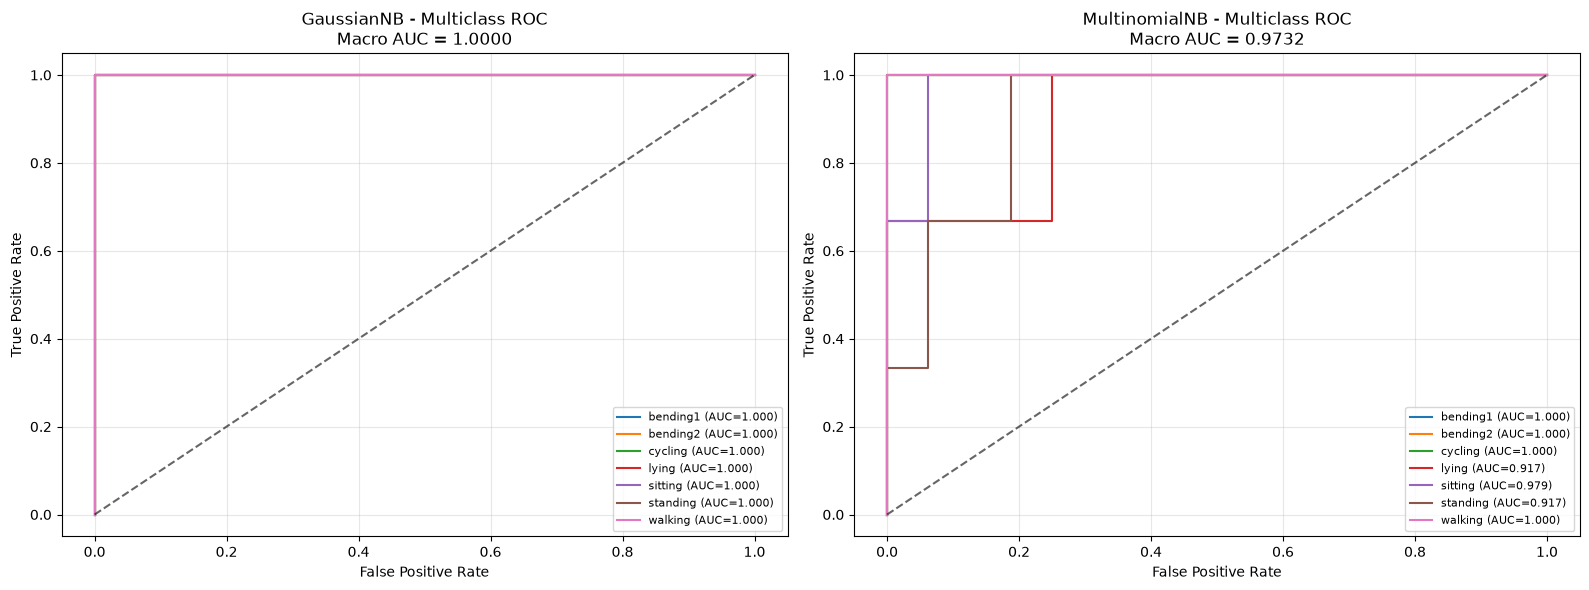

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (name, result) in zip(axes, nb_test_results.items()):

    model = result["model"]
    probabilities = result["y_prob"]

    class_auc_scores = []

    for i, activity in enumerate(model.classes_):


        y_binary = (y_test_multi == activity).astype(int)

        fpr, tpr, _ = roc_curve(
            y_binary,
            probabilities[:, i]
        )

        class_auc = auc(fpr, tpr)
        class_auc_scores.append(class_auc)

        ax.plot(
            fpr,
            tpr,
            label=f"{activity} (AUC={class_auc:.3f})"
        )

    macro_auc = np.mean(class_auc_scores)

    ax.plot([0, 1], [0, 1], "k--", alpha=0.6)

    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(
        f"{name} - Multiclass ROC\n"
        f"Macro AUC = {macro_auc:.4f}"
    )
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Compare

In [28]:
best_multi_model = multi_best_models[best_l_multi]


X_test_multi = extract_features(raw_test, best_l_multi)


y_test_multi = test_df["activity"].to_numpy()


y_pred_multi = best_multi_model.predict(X_test_multi)


test_accuracy_multi = accuracy_score(
    y_test_multi, y_pred_multi
)

test_error_multi = 1 - test_accuracy_multi

test_balanced_multi = balanced_accuracy_score(
    y_test_multi, y_pred_multi
)

print("Multinomial Logistic Regression Results")
print("Test Accuracy:", round(test_accuracy_multi, 4))
print("Test Error:", round(test_error_multi, 4))
print("Test Balanced Accuracy:", round(test_balanced_multi, 4))

Multinomial Logistic Regression Results
Test Accuracy: 0.8947
Test Error: 0.1053
Test Balanced Accuracy: 0.9048


In [29]:
comparison_nb = pd.DataFrame([
    {
        "Model": "L1 Multinomial Logistic Regression",
        "Best l": best_l_multi,
        "CV Balanced Accuracy": best_cv_multi,
        "Test Accuracy": test_accuracy_multi,
        "Test Error": test_error_multi
    },
    {
        "Model": "Gaussian Naive Bayes",
        "Best l": best_l_gaussian,
        "CV Balanced Accuracy": best_cv_gaussian,
        "Test Accuracy": nb_test_results["GaussianNB"]["accuracy"],
        "Test Error": nb_test_results["GaussianNB"]["test_error"]
    },
    {
        "Model": "Multinomial Naive Bayes",
        "Best l": best_l_multinomial,
        "CV Balanced Accuracy": best_cv_multinomial,
        "Test Accuracy": nb_test_results["MultinomialNB"]["accuracy"],
        "Test Error": nb_test_results["MultinomialNB"]["test_error"]
    }
])

display(comparison_nb.round(4))

,Model,Best l,CV Balanced Accuracy,Test Accuracy,Test Error
0,L1 Multinomial Logistic Regression,1,0.8810,0.8947,0.1053
1,Gaussian Naive Bayes,1,0.8929,0.9474,0.0526
2,Multinomial Naive Bayes,2,0.8155,0.7895,0.2105


2.c.iii.

Based on my experimental results, Gaussian Naive Bayes is the best-performing classifier for multiclass activity recognition on the AReM dataset.

3.

4.8.3. 

In QDA, each class $k$ has its own mean $\mu_k$ and variance $\sigma_k^2$.

The normal distribution for class $k$ is:

$$
f_k(x)=\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)
$$

Using Bayes' rule, we classify an observation into the class with the highest discriminant score:

$$
\delta_k(x)=\log(\pi_k)-\log(\sigma_k)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
$$

where $\pi_k$ is the prior probability of class $k$.

**Step 1: Expand the squared term**

Since

$$
(x-\mu_k)^2=x^2-2x\mu_k+\mu_k^2
$$

we obtain:

$$
\delta_k(x)=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k x}{\sigma_k^2}
-\frac{\mu_k^2}{2\sigma_k^2}
-\log(\sigma_k)+\log(\pi_k)
$$

**Step 2: Observe the quadratic term**

The discriminant function contains:

$$
-\frac{x^2}{2\sigma_k^2}
$$

Because each class can have a different variance $\sigma_k^2$, the coefficients of $x^2$ can differ between classes.

Therefore, when comparing two classes, the quadratic terms generally do not cancel out.

**Conclusion**

The Bayes classifier in QDA is quadratic rather than linear because the class-specific variances introduce an $x^2$ term into the discriminant functions.

Since the variances can differ, these quadratic terms generally do not cancel when comparing classes.

If all classes had the same variance, the quadratic terms would cancel, resulting in a linear classifier (LDA).

Thus, QDA generally produces quadratic decision boundaries, although special cases with equal variances can produce linear boundaries.


4.8.7.


 Problem 7: Bayes' Theorem

We use Bayes' theorem to calculate the probability that a company issues a dividend given that its profit was $X=4$.

**Step 1: given-**

- Mean profit for dividend companies: $\mu_{\text{Yes}}=10$
- Mean profit for non-dividend companies: $\mu_{\text{No}}=0$
- Variance: $\sigma^2=36$
- Probability of issuing a dividend: $P(\text{Yes})=0.8$
- Probability of not issuing a dividend: $P(\text{No})=0.2$

**Step 2: Apply Bayes' theorem**

$$
P(\text{Yes}\mid X=4)=
\frac{0.8f_{\text{Yes}}(4)}
{0.8f_{\text{Yes}}(4)+0.2f_{\text{No}}(4)}
$$

Using the normal distribution formula:

$$
f(x)=\frac{1}{\sqrt{2\pi(36)}}e^{-\frac{(x-\mu)^2}{72}}
$$

Substitute $X=4$ for both classes:

$$
f_{\text{Yes}}(4)=\frac{1}{\sqrt{72\pi}}e^{-\frac{(4-10)^2}{72}}
$$

$$
f_{\text{No}}(4)=\frac{1}{\sqrt{72\pi}}e^{-\frac{(4-0)^2}{72}}
$$

**Step 3: Calculate the probability**

The common factor $\frac{1}{\sqrt{72\pi}}$ cancels out:

$$
P(\text{Yes}\mid X=4)=
\frac{0.8e^{-36/72}}
{0.8e^{-36/72}+0.2e^{-16/72}}
$$

Simplifying:

$$
=\frac{0.8(0.6065)}
{0.8(0.6065)+0.2(0.8007)}
$$

$$
\boxed{P(\text{Yes}\mid X=4)\approx 0.752}
$$

**Conclusion**

There is approximately a 75.2% probability.

